# LAB 1 - PHẦN 2 - BÀI 2 (TRANG 37–38)
## Khai phá tập phổ biến và luật kết hợp trên dữ liệu Online Retail (United Kingdom)

- **Họ tên sinh viên:** `Nguyễn Phạm Bảo Khanh`
- **MSSV:** `6451071033`
- **Tập dữ liệu:** `Dataset/Online Retail.xlsx` (hỗ trợ chạy cục bộ và Google Colab)

## 0. Thiết lập môi trường, thư viện và hàm tải dữ liệu

- Khai báo thông tin sinh viên (`STUDENT_NAME`, `MSSV`).
- Tự động kiểm tra và cài đặt `mlxtend`, `openpyxl` nếu chưa có.
- Hàm `get_dataset_path("Online Retail.xlsx")` hỗ trợ 3 chế độ theo thứ tự ưu tiên:
  1. Kiểm tra trực tiếp trong `./Dataset/Online Retail.xlsx`.
  2. Nếu chạy trên Google Colab, mount Google Drive tại `/content/drive` và kiểm tra `/content/drive/MyDrive/Dataset/Online Retail.xlsx`.
  3. Nếu chưa có sẵn, tự động tải thư mục Dataset bằng `gdown`.

In [1]:
import importlib.util
import os
import subprocess
import sys
import time

STUDENT_NAME = "Nguyễn Phạm Bảo Khanh"
MSSV = "6451071033"
DATASET_FOLDER_URL = "https://drive.google.com/drive/folders/1rv5SiO5zFlU-cyEXul09OpCvTXrdjG1m?usp=sharing"

for pkg in ["mlxtend", "openpyxl"]:
    if importlib.util.find_spec(pkg) is None:
        print(f"Đang cài đặt thư viện còn thiếu: {pkg}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import mlxtend
import openpyxl
from IPython.display import display
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

%matplotlib inline


def get_dataset_path(filename: str) -> str:
    local_path = os.path.join("Dataset", filename)
    if os.path.exists(local_path):
        print(f"Đang sử dụng dữ liệu cục bộ: {local_path}")
        return local_path

    if "google.colab" in sys.modules:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
            drive_path = os.path.join("/content/drive/MyDrive/Dataset", filename)
            if os.path.exists(drive_path):
                print(f"Đang sử dụng dữ liệu từ Google Drive: {drive_path}")
                return drive_path
        except Exception as err:
            print(f"Không thể truy cập Google Drive ({err}), chuyển sang tải bằng gdown...")

    if importlib.util.find_spec("gdown") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
    os.makedirs("Dataset", exist_ok=True)
    print("Đang tải dữ liệu từ Google Drive bằng gdown...")
    subprocess.check_call([
        sys.executable, "-m", "gdown",
        "--folder", DATASET_FOLDER_URL,
        "-O", "Dataset"
    ])
    if os.path.exists(local_path):
        return local_path
    for root, _, files in os.walk("Dataset"):
        if filename in files:
            return os.path.join(root, filename)
    raise FileNotFoundError(f"Không tìm thấy tập tin '{filename}' sau khi tải về Dataset/.")


print(f"{STUDENT_NAME} - {MSSV}")
print(f"Phiên bản thư viện: pandas={pd.__version__}, openpyxl={openpyxl.__version__}, mlxtend={mlxtend.__version__}, seaborn={sns.__version__}")

Nguyễn Phạm Bảo Khanh - 6451071033
Phiên bản thư viện: pandas=3.1.1, openpyxl=3.1.5, mlxtend=0.25.0, seaborn=0.13.2


### Câu 1: Đọc dữ liệu vào chương trình

Sử dụng `pandas.read_excel(..., engine='openpyxl')` để đọc tập tin `Online Retail.xlsx` (tương thích với định dạng `.xlsx` hiện đại thay cho `xlrd`), sau đó hiển thị `shape`, `info()` và `head()`.

In [2]:
print(f"{STUDENT_NAME} - {MSSV}")
data_path = get_dataset_path("Online Retail.xlsx")
df = pd.read_excel(data_path, engine="openpyxl")

print(f"Kích thước dữ liệu (shape): {df.shape}")
print("\nThông tin cấu trúc dữ liệu (info):")
df.info()
print("\n5 dòng dữ liệu đầu tiên (head):")
display(df.head())

Nguyễn Phạm Bảo Khanh - 6451071033
Đang sử dụng dữ liệu cục bộ: Dataset\Online Retail.xlsx
Kích thước dữ liệu (shape): (541909, 8)

Thông tin cấu trúc dữ liệu (info):
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB

5 dòng dữ liệu đầu tiên (head):


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### Câu 2: Tiền xử lý dữ liệu

- Cắt bỏ khoảng trắng thừa ở đầu và cuối tên mặt hàng (`Description`).
- Xóa các dòng bị thiếu số hóa đơn (`InvoiceNo`).
- Chuyển cột `InvoiceNo` về kiểu chuỗi (`str`) và hiển thị 10 dòng đầu tiên sau khi làm sạch.

In [3]:
print(f"{STUDENT_NAME} - {MSSV}")
df["Description"] = df["Description"].str.strip()
df = df.dropna(axis=0, subset=["InvoiceNo"]).copy()
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

print(f"Kích thước dữ liệu sau tiền xử lý: {df.shape}")
print("Kiểu dữ liệu cột InvoiceNo:", df["InvoiceNo"].dtype)
print("\n10 dòng đầu tiên sau khi làm sạch:")
display(df.head(10))

Nguyễn Phạm Bảo Khanh - 6451071033
Kích thước dữ liệu sau tiền xử lý: (541909, 8)
Kiểu dữ liệu cột InvoiceNo: str

10 dòng đầu tiên sau khi làm sạch:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


### Câu 3: Kiểm tra và xóa các hóa đơn tín dụng (chứa ký tự `'C'` trong `InvoiceNo`)

Các hóa đơn tín dụng (credit/cancellation) có chứa ký tự `'C'` ở số hóa đơn (`InvoiceNo`) và thường mang số lượng âm. Cần kiểm tra ví dụ minh họa, lọc bỏ toàn bộ các dòng này và thống kê số dòng trước/sau khi xóa.

In [4]:
print(f"{STUDENT_NAME} - {MSSV}")
rows_before = len(df)
credit_mask = df["InvoiceNo"].str.contains("C", na=False)

print(f"Số dòng trước khi xóa hóa đơn tín dụng: {rows_before:,}")
print(f"Số dòng hóa đơn tín dụng (chứa 'C'): {credit_mask.sum():,}")
print("\nVí dụ một số hóa đơn tín dụng:")
display(df[credit_mask].head())

df = df[~credit_mask].copy()
rows_after = len(df)
print(f"\nSố dòng sau khi xóa hóa đơn tín dụng: {rows_after:,}")
print(f"Tổng số dòng đã loại bỏ: {rows_before - rows_after:,}")

Nguyễn Phạm Bảo Khanh - 6451071033
Số dòng trước khi xóa hóa đơn tín dụng: 541,909
Số dòng hóa đơn tín dụng (chứa 'C'): 9,288

Ví dụ một số hóa đơn tín dụng:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom



Số dòng sau khi xóa hóa đơn tín dụng: 532,621
Tổng số dòng đã loại bỏ: 9,288


### Câu 4: Thống kê số dòng dữ liệu theo từng quốc gia

Thống kê tần suất xuất hiện theo cột `Country` và vẽ biểu đồ thanh ngang (`barh`, `figsize=(15, 10)`).

Nguyễn Phạm Bảo Khanh - 6451071033
Tổng số quốc gia có trong dữ liệu: 38

Top 10 quốc gia có số dòng dữ liệu cao nhất:


,Số dòng
Country,
United Kingdom,487622
Germany,9042
France,8408
EIRE,7894
Spain,2485
Netherlands,2363
Belgium,2031
Switzerland,1967
Portugal,1501


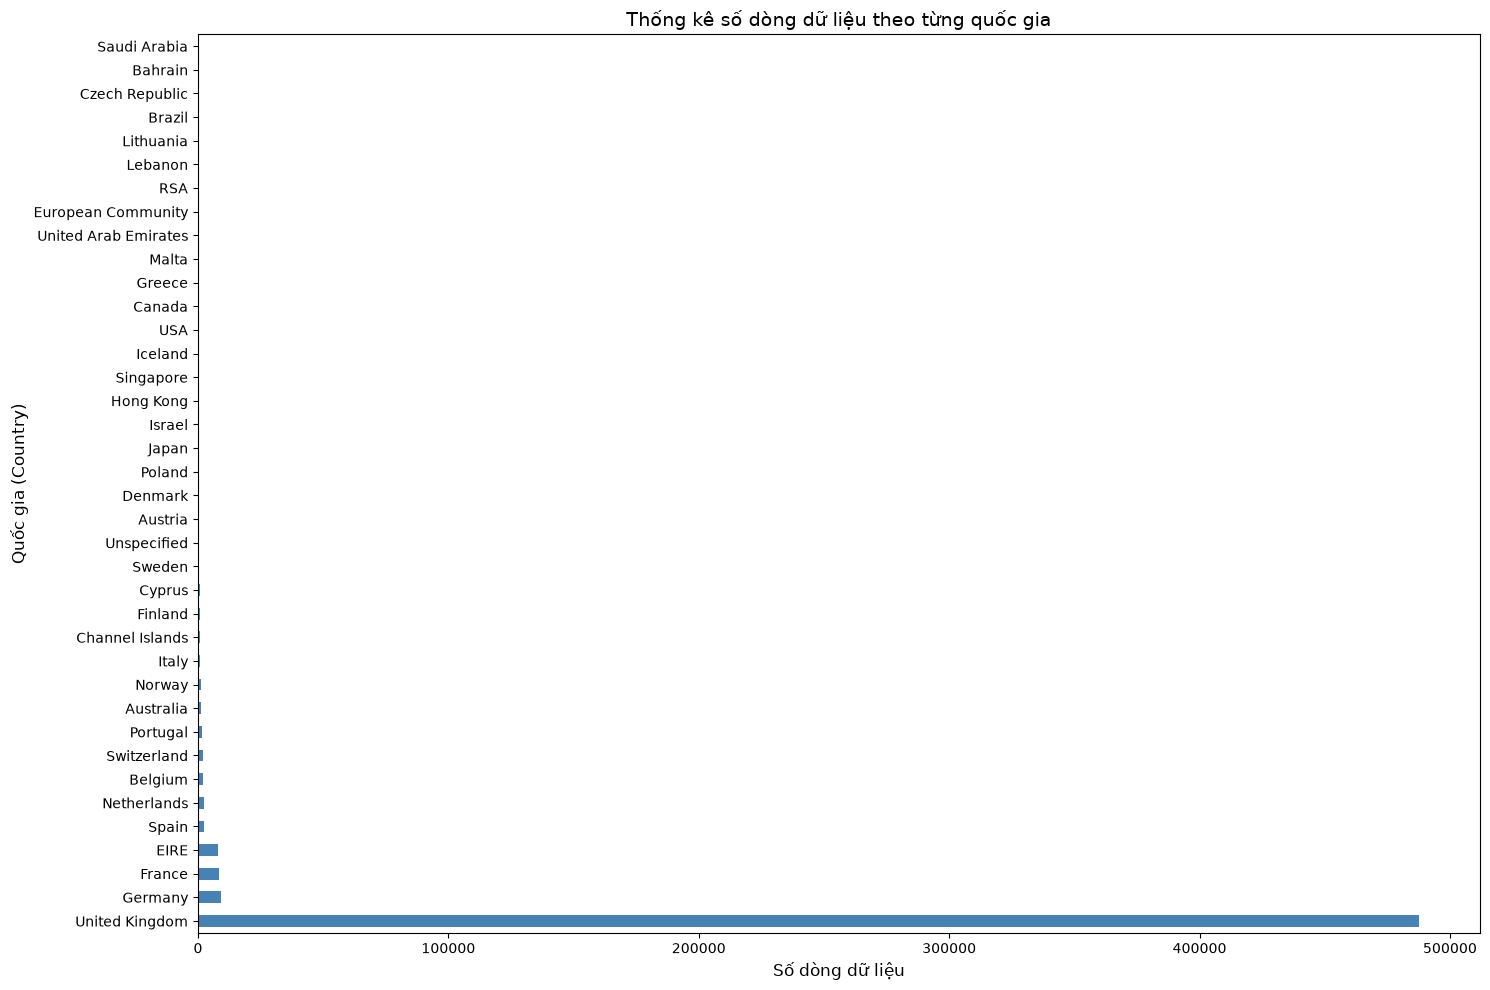

In [5]:
print(f"{STUDENT_NAME} - {MSSV}")
country_counts = df["Country"].value_counts()
print(f"Tổng số quốc gia có trong dữ liệu: {len(country_counts)}")
print("\nTop 10 quốc gia có số dòng dữ liệu cao nhất:")
display(country_counts.head(10).to_frame(name="Số dòng"))

ax = country_counts.plot(kind="barh", figsize=(15, 10), color="steelblue")
ax.set_title("Thống kê số dòng dữ liệu theo từng quốc gia", fontsize=14)
ax.set_xlabel("Số dòng dữ liệu", fontsize=12)
ax.set_ylabel("Quốc gia (Country)", fontsize=12)
plt.tight_layout()
plt.show()

**Nhận xét Câu 4:**
- Dữ liệu gồm **38 quốc gia/vùng lãnh thổ**, trong đó **United Kingdom** chiếm tỷ trọng áp đảo với **487,622** dòng (~91.55% tổng dữ liệu sau khi loại bỏ hóa đơn `'C'`).
- Các quốc gia đứng kế tiếp có số lượng giao dịch nhỏ hơn rất nhiều, như **Germany** (9,042), **France** (8,408) và **EIRE** (7,894).

### Câu 5: Lọc dữ liệu `'United Kingdom'` và gom nhóm `Quantity` theo `InvoiceNo` và `Description`

Chỉ giữ lại các dòng giao dịch thuộc `'United Kingdom'`, sau đó gom nhóm theo `['InvoiceNo', 'Description']` và tính tổng cột `Quantity`.

In [6]:
print(f"{STUDENT_NAME} - {MSSV}")
uk_df = df[df["Country"] == "United Kingdom"]
print(f"Số dòng dữ liệu thuộc United Kingdom: {len(uk_df):,}")

basket_grouped = uk_df.groupby(["InvoiceNo", "Description"])["Quantity"].sum()
print(f"Số cặp (InvoiceNo, Description) sau gom nhóm: {len(basket_grouped):,}")
print("\n10 dòng đầu tiên sau khi gom nhóm Quantity:")
display(basket_grouped.head(10).to_frame())

Nguyễn Phạm Bảo Khanh - 6451071033
Số dòng dữ liệu thuộc United Kingdom: 487,622
Số cặp (InvoiceNo, Description) sau gom nhóm: 475,560

10 dòng đầu tiên sau khi gom nhóm Quantity:


Quantity
InvoiceNo Description                                  
536365    CREAM CUPID HEARTS COAT HANGER              8
          GLASS STAR FROSTED T-LIGHT HOLDER           6
          KNITTED UNION FLAG HOT WATER BOTTLE         6
          RED WOOLLY HOTTIE WHITE HEART.              6
          SET 7 BABUSHKA NESTING BOXES                2
          WHITE HANGING HEART T-LIGHT HOLDER          6
          WHITE METAL LANTERN                         6
536366    HAND WARMER RED POLKA DOT                   6
          HAND WARMER UNION JACK                      6
536367    ASSORTED COLOUR BIRD ORNAMENT              32

### Câu 6: Chuyển đổi dữ liệu về dạng hot encoding

Thực hiện `unstack().reset_index().fillna(0).set_index('InvoiceNo')` để đưa dữ liệu về ma trận giỏ hàng mà mỗi dòng là một hóa đơn (`InvoiceNo`) và mỗi cột là một mặt hàng (`Description`).

In [7]:
print(f"{STUDENT_NAME} - {MSSV}")
basket = basket_grouped.unstack().reset_index().fillna(0).set_index("InvoiceNo")
print(f"Kích thước ma trận giỏ hàng (hot encoding): {basket.shape}")
print("\n10 hóa đơn đầu tiên ở dạng hot encoding:")
display(basket.head(10))

Nguyễn Phạm Bảo Khanh - 6451071033
Kích thước ma trận giỏ hàng (hot encoding): (18667, 4175)

10 hóa đơn đầu tiên ở dạng hot encoding:


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,...,wrongly coded 20713,wrongly coded 23343,wrongly coded-23343,wrongly marked,wrongly marked 23343,wrongly marked carton 22804,wrongly marked. 23343 in box,wrongly sold (22719) barcode,wrongly sold as sets,wrongly sold sets
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536365,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536366,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536367,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536368,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536369,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536371,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536372,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536373,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536374,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### Câu 7: Chuyển đổi từ dạng hot encoding thành one-hot encoding

Ánh xạ từng giá trị trong ma trận giỏ hàng về nhị phân (`0` nếu `<= 0`, ngược lại `1`). Do `pandas 3.x` đã loại bỏ `DataFrame.applymap()`, ta sử dụng `basket.map(encode_data)`.

In [8]:
print(f"{STUDENT_NAME} - {MSSV}")

def encode_data(datapoint):
    if datapoint <= 0:
        return 0
    return 1

basket = basket.map(encode_data)
print(f"Kích thước ma trận sau one-hot encoding: {basket.shape}")
print("Thống kê kiểu dữ liệu các cột:", dict(basket.dtypes.value_counts()))
print("\n5 hóa đơn đầu tiên ở dạng one-hot encoding (0/1):")
display(basket.head(5))

Nguyễn Phạm Bảo Khanh - 6451071033
Kích thước ma trận sau one-hot encoding: (18667, 4175)
Thống kê kiểu dữ liệu các cột: {dtype('int64'): np.int64(4175)}

5 hóa đơn đầu tiên ở dạng one-hot encoding (0/1):


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,...,wrongly coded 20713,wrongly coded 23343,wrongly coded-23343,wrongly marked,wrongly marked 23343,wrongly marked carton 22804,wrongly marked. 23343 in box,wrongly sold (22719) barcode,wrongly sold as sets,wrongly sold sets
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536365,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536366,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536367,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536368,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
536369,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Câu 8: Xóa cột `'POSTAGE'`

Cột `'POSTAGE'` biểu thị cước phí vận chuyển chứ không phải sản phẩm mua sắm thực tế, vì vậy cần loại bỏ khỏi ma trận giỏ hàng (`errors='ignore'` để an toàn).

In [9]:
print(f"{STUDENT_NAME} - {MSSV}")
cols_before = basket.shape[1]
has_postage = "POSTAGE" in basket.columns
basket = basket.drop("POSTAGE", axis=1, errors="ignore")

print(f"Cột 'POSTAGE' tồn tại trước khi xóa: {has_postage}")
print(f"Số cột trước khi xóa: {cols_before:,} -> Sau khi xóa: {basket.shape[1]:,}")
print(f"Kích thước ma trận basket cuối cùng: {basket.shape}")

Nguyễn Phạm Bảo Khanh - 6451071033
Cột 'POSTAGE' tồn tại trước khi xóa: True
Số cột trước khi xóa: 4,175 -> Sau khi xóa: 4,174
Kích thước ma trận basket cuối cùng: (18667, 4174)


### Câu 9: Tìm tập phổ biến bằng thuật toán Apriori (`min_support = 0.03`)

Chuyển ma trận `basket` sang kiểu `bool` theo khuyến nghị của `mlxtend` (giúp tăng tốc tính toán và tránh `DeprecationWarning` cho DataFrame không phải `bool`), chạy `apriori(..., min_support=0.03, use_colnames=True)` và đo thời gian thực thi bằng `time.perf_counter()`.

In [10]:
print(f"{STUDENT_NAME} - {MSSV}")
basket_bool = basket.astype(bool)

t0 = time.perf_counter()
itemsets_apriori = apriori(basket_bool, min_support=0.03, use_colnames=True)
apriori_time = time.perf_counter() - t0

print(f"Số tập phổ biến tìm được (Apriori, min_support=0.03): {len(itemsets_apriori)}")
print(f"Thời gian thực thi Apriori: {apriori_time:.4f} giây")
print("\n10 tập phổ biến đầu tiên:")
display(itemsets_apriori.head(10))

Nguyễn Phạm Bảo Khanh - 6451071033
Số tập phổ biến tìm được (Apriori, min_support=0.03): 131
Thời gian thực thi Apriori: 0.3683 giây

10 tập phổ biến đầu tiên:


,support,itemsets
0,0.045803,frozenset({6 RIBBONS RUSTIC CHARM})
1,0.031124,frozenset({60 CAKE CASES VINTAGE CHRISTMAS})
2,0.040339,frozenset({60 TEATIME FAIRY CAKE CASES})
3,0.046928,frozenset({ALARM CLOCK BAKELIKE GREEN})
4,0.035142,frozenset({ALARM CLOCK BAKELIKE PINK})
5,0.049821,frozenset({ALARM CLOCK BAKELIKE RED})
6,0.036214,frozenset({ANTIQUE SILVER T-LIGHT GLASS})
7,0.073445,frozenset({ASSORTED COLOUR BIRD ORNAMENT})
8,0.042267,frozenset({BAKING SET 9 PIECE RETROSPOT})
9,0.035089,frozenset({BATHROOM METAL SIGN})


### Câu 10: Tạo luật kết hợp với `min_confidence = 50%` và in ra các luật

Sinh tập luật từ kết quả Apriori bằng `association_rules(..., metric='confidence', min_threshold=0.5)`, chuẩn hóa hiển thị các tập mục `frozenset` bằng `', '.join(sorted(list(x)))` và in toàn bộ các luật kèm `support`, `confidence`, `lift`.

In [11]:
print(f"{STUDENT_NAME} - {MSSV}")
rules_apriori = association_rules(itemsets_apriori, metric="confidence", min_threshold=0.5)

print(f"Số lượng luật kết hợp tìm được (min_confidence=0.5): {len(rules_apriori)}")
print("\nThông tin bảng luật (rules.info()):")
rules_apriori.info()

rules_apriori_fmt = rules_apriori.copy()
rules_apriori_fmt["antecedents"] = rules_apriori_fmt["antecedents"].apply(lambda x: ", ".join(sorted(list(x))))
rules_apriori_fmt["consequents"] = rules_apriori_fmt["consequents"].apply(lambda x: ", ".join(sorted(list(x))))

print("\nDanh sách tất cả các luật kết hợp (Apriori):")
for idx, row in rules_apriori_fmt.iterrows():
    print(
        f"{idx + 1:2d}. {row['antecedents']} => {row['consequents']} "
        f"[support={row['support']:.4f}, confidence={row['confidence']:.4f}, lift={row['lift']:.4f}]"
    )

display(rules_apriori_fmt[["antecedents", "consequents", "support", "confidence", "lift"]])

Nguyễn Phạm Bảo Khanh - 6451071033
Số lượng luật kết hợp tìm được (min_confidence=0.5): 10

Thông tin bảng luật (rules.info()):
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   antecedents         10 non-null     object 
 1   consequents         10 non-null     object 
 2   antecedent support  10 non-null     float64
 3   consequent support  10 non-null     float64
 4   support             10 non-null     float64
 5   confidence          10 non-null     float64
 6   lift                10 non-null     float64
 7   representativity    10 non-null     float64
 8   leverage            10 non-null     float64
 9   conviction          10 non-null     float64
 10  zhangs_metric       10 non-null     float64
 11  jaccard             10 non-null     float64
 12  certainty           10 non-null     float64
 13  kulczynski          10 non-null     float

,antecedents,consequents,support,confidence,lift
0,ALARM CLOCK BAKELIKE GREEN,ALARM CLOCK BAKELIKE RED,0.030160,0.642694,12.900183
1,ALARM CLOCK BAKELIKE RED,ALARM CLOCK BAKELIKE GREEN,0.030160,0.605376,12.900183
2,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.030910,0.617773,16.403939
3,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.030910,0.820768,16.403939
4,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.037553,0.750535,14.639752
5,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.037553,0.732497,14.639752
6,JUMBO BAG BAROQUE BLACK WHITE,JUMBO BAG RED RETROSPOT,0.030535,0.626374,6.033290
7,JUMBO BAG PINK POLKADOT,JUMBO BAG RED RETROSPOT,0.042053,0.677308,6.523895
8,JUMBO SHOPPER VINTAGE RED PAISLEY,JUMBO BAG RED RETROSPOT,0.035196,0.579876,5.585425
9,JUMBO STORAGE BAG SUKI,JUMBO BAG RED RETROSPOT,0.037392,0.617699,5.949737


### Câu 11: Biểu diễn độ hỗ trợ và độ tin cậy của tập luật lên đồ thị phân tán (scatter plot)

Vẽ đồ thị phân tán với `plt.figure(figsize=(6, 6))` và `sns.regplot(x=support, y=confidence, fit_reg=False)`.

Nguyễn Phạm Bảo Khanh - 6451071033


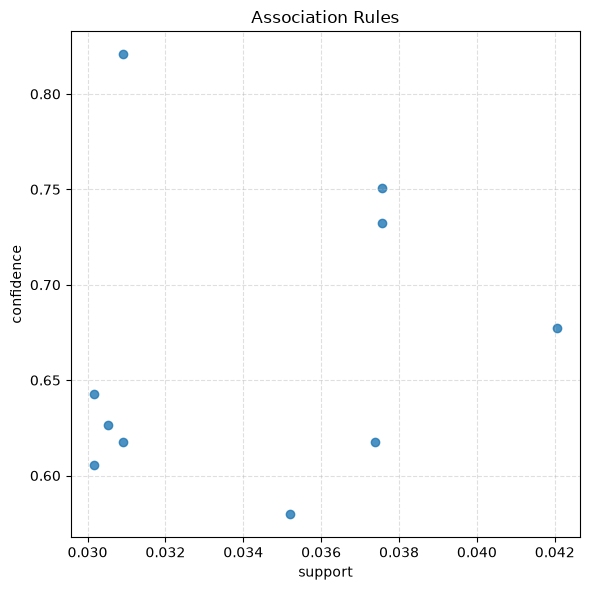

In [12]:
print(f"{STUDENT_NAME} - {MSSV}")
support = rules_apriori["support"].values
confidence = rules_apriori["confidence"].values

plt.figure(figsize=(6, 6))
plt.title("Association Rules")
plt.xlabel("support")
plt.ylabel("confidence")
sns.regplot(x=support, y=confidence, fit_reg=False)
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

**Nhận xét Câu 11:**
- Biểu đồ hiển thị 10 điểm tương ứng với 10 luật kết hợp tìm được ở Câu 10.
- Độ hỗ trợ (`support`) tập trung trong khoảng **0.030 – 0.042** (3.0% – 4.2% số hóa đơn tại UK), còn độ tin cậy (`confidence`) dao động từ khoảng **0.580 – 0.821**.
- Các luật có độ tin cậy cao nhất thuộc nhóm sản phẩm tách trà *Regency Teacup and Saucer* (lên đến ~82.1%) và nhóm túi *Jumbo Bag*.

### Câu 12: Tìm tập phổ biến và luật kết hợp bằng FP-Growth và so sánh với Apriori

Áp dụng `fpgrowth(basket_bool, min_support=0.03, use_colnames=True)` và `association_rules(..., metric='confidence', min_threshold=0.5)`, sau đó đối chiếu số tập phổ biến, tập luật sinh ra và thời gian chạy giữa hai thuật toán.

Nguyễn Phạm Bảo Khanh - 6451071033
Số tập phổ biến (FP-Growth): 131
Số luật kết hợp (FP-Growth): 10
Thời gian thực thi FP-Growth: 1.2026 giây

Danh sách tất cả các luật kết hợp (FP-Growth):
 1. JUMBO BAG PINK POLKADOT => JUMBO BAG RED RETROSPOT [support=0.0421, confidence=0.6773, lift=6.5239]
 2. JUMBO STORAGE BAG SUKI => JUMBO BAG RED RETROSPOT [support=0.0374, confidence=0.6177, lift=5.9497]
 3. JUMBO  BAG BAROQUE BLACK WHITE => JUMBO BAG RED RETROSPOT [support=0.0305, confidence=0.6264, lift=6.0333]
 4. JUMBO SHOPPER VINTAGE RED PAISLEY => JUMBO BAG RED RETROSPOT [support=0.0352, confidence=0.5799, lift=5.5854]
 5. ALARM CLOCK BAKELIKE GREEN => ALARM CLOCK BAKELIKE RED [support=0.0302, confidence=0.6427, lift=12.9002]
 6. ALARM CLOCK BAKELIKE RED => ALARM CLOCK BAKELIKE GREEN [support=0.0302, confidence=0.6054, lift=12.9002]
 7. GREEN REGENCY TEACUP AND SAUCER => ROSES REGENCY TEACUP AND SAUCER [support=0.0376, confidence=0.7505, lift=14.6398]
 8. ROSES REGENCY TEACUP AND SAUCER => 

,Thuật toán,Số tập phổ biến,Số luật kết hợp,Thời gian thực thi (giây)
0,Apriori,131,10,0.3683
1,FP-Growth,131,10,1.2026


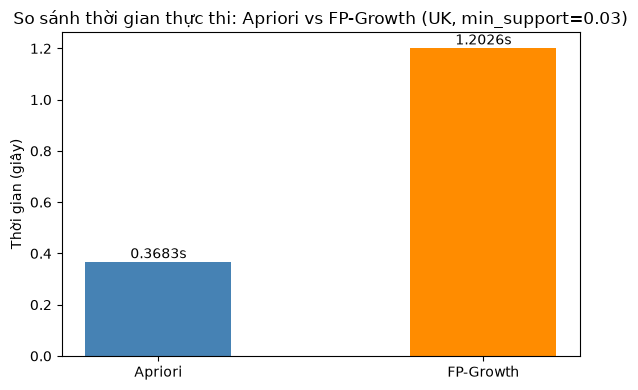

In [13]:
print(f"{STUDENT_NAME} - {MSSV}")

t0 = time.perf_counter()
itemsets_fpgrowth = fpgrowth(basket_bool, min_support=0.03, use_colnames=True)
fpgrowth_time = time.perf_counter() - t0

rules_fpgrowth = association_rules(itemsets_fpgrowth, metric="confidence", min_threshold=0.5)

print(f"Số tập phổ biến (FP-Growth): {len(itemsets_fpgrowth)}")
print(f"Số luật kết hợp (FP-Growth): {len(rules_fpgrowth)}")
print(f"Thời gian thực thi FP-Growth: {fpgrowth_time:.4f} giây")

rules_fp_fmt = rules_fpgrowth.copy()
rules_fp_fmt["antecedents"] = rules_fp_fmt["antecedents"].apply(lambda x: ", ".join(sorted(list(x))))
rules_fp_fmt["consequents"] = rules_fp_fmt["consequents"].apply(lambda x: ", ".join(sorted(list(x))))

print("\nDanh sách tất cả các luật kết hợp (FP-Growth):")
for idx, row in rules_fp_fmt.iterrows():
    print(
        f"{idx + 1:2d}. {row['antecedents']} => {row['consequents']} "
        f"[support={row['support']:.4f}, confidence={row['confidence']:.4f}, lift={row['lift']:.4f}]"
    )

# Kiểm tra khớp tập phổ biến và tập luật giữa Apriori và FP-Growth
ap_items = {frozenset(x): round(s, 10) for x, s in zip(itemsets_apriori["itemsets"], itemsets_apriori["support"])}
fp_items = {frozenset(x): round(s, 10) for x, s in zip(itemsets_fpgrowth["itemsets"], itemsets_fpgrowth["support"])}
itemsets_match = (ap_items == fp_items)

ap_rules_set = {
    (frozenset(a), frozenset(c)): (round(s, 10), round(cf, 10), round(lf, 10))
    for a, c, s, cf, lf in zip(
        rules_apriori["antecedents"], rules_apriori["consequents"],
        rules_apriori["support"], rules_apriori["confidence"], rules_apriori["lift"]
    )
}
fp_rules_set = {
    (frozenset(a), frozenset(c)): (round(s, 10), round(cf, 10), round(lf, 10))
    for a, c, s, cf, lf in zip(
        rules_fpgrowth["antecedents"], rules_fpgrowth["consequents"],
        rules_fpgrowth["support"], rules_fpgrowth["confidence"], rules_fpgrowth["lift"]
    )
}
rules_match = (ap_rules_set == fp_rules_set)

print(f"\nTập phổ biến khớp 100%: {itemsets_match}")
print(f"Tập luật kết hợp khớp 100%: {rules_match}")

comparison_df = pd.DataFrame({
    "Thuật toán": ["Apriori", "FP-Growth"],
    "Số tập phổ biến": [len(itemsets_apriori), len(itemsets_fpgrowth)],
    "Số luật kết hợp": [len(rules_apriori), len(rules_fpgrowth)],
    "Thời gian thực thi (giây)": [round(apriori_time, 4), round(fpgrowth_time, 4)],
})
display(comparison_df)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(comparison_df["Thuật toán"], comparison_df["Thời gian thực thi (giây)"], color=["steelblue", "darkorange"], width=0.45)
ax.set_title("So sánh thời gian thực thi: Apriori vs FP-Growth (UK, min_support=0.03)")
ax.set_ylabel("Thời gian (giây)")
for bar in bars:
    val = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2, val, f"{val:.4f}s", ha="center", va="bottom")
plt.tight_layout()
plt.show()

**Nhận xét & So sánh Apriori vs FP-Growth (Câu 12):**
1. **Về kết quả khai phá (tập phổ biến & luật kết hợp):**
   - Cả hai thuật toán đều tìm được đúng **131 tập phổ biến** (`min_support = 0.03`) và sinh ra đúng **10 luật kết hợp** (`min_confidence = 0.5`).
   - Đối chiếu từng tập mục và từng luật (`support`, `confidence`, `lift`) đều **khớp 100%**, vì cả Apriori và FP-Growth đều là thuật toán khai phá chính xác (exact frequent pattern mining).
2. **Về thời gian thực thi & cơ chế thuật toán:**
   - Trên ma trận giỏ hàng UK kích thước `(18,667 x 4,174)` kiểu `bool` với ngưỡng `min_support = 0.03` tương đối cao (tập phổ biến lớn nhất chỉ gồm 2 mặt hàng), **Apriori** thực thi nhanh hơn **FP-Growth**.
   - Nguyên nhân là ở ngưỡng hỗ trợ 3%, số ứng viên phát sinh ở Apriori rất ít (chỉ cần 2 lượt quét trên ma trận nhị phân được vector hóa bằng NumPy), trong khi FP-Growth phải tốn chi phí xây dựng cây FP-Tree và duyệt đệ quy các cây điều kiện (conditional FP-Tree) trên 18,667 giao dịch.
   - Ngược lại, khi hạ `min_support` xuống rất thấp (dữ liệu có nhiều tập phổ biến dài, số lượng ứng viên tăng theo hàm mũ), FP-Growth sẽ vượt trội hơn Apriori nhờ không cần sinh tập ứng viên.